# Loan Default Risk Prediction for Small-Business Lending

**Author:** Ahmed Alazzawi  
**Origin:** Originally developed as an academic project in data mining and predictive analytics; subsequently audited, corrected, and re-executed for professional portfolio publication.

This notebook predicts whether a small-business loan applicant will default, using only information available at the time of application. It compares a Decision Tree and a Neural Network (the original project's models) against a majority-class baseline and an interpretable Logistic Regression benchmark, and adds an unsupervised K-Means segmentation of applicants.

**Revision Note:** The original submission contained a target-leakage error (the outcome variable `Defaulted` was included in the K-Means clustering inputs, and the resulting cluster labels were fed to the classifiers), fitted preprocessing on all data before cross-validation, used no held-out test set, and reported two invalid metrics. All of these issues have been corrected. Every result presented in this notebook comes from the revised execution. See Section 5 and the README for details.

### Contents

1. Business Problem & Objectives
2. Dataset Overview
3. Data Quality & Preparation
4. Exploratory Data Analysis
5. Feature Selection & Leakage Prevention
6. Model Development
7. Model Evaluation & Comparison
8. Key Analytical Findings
9. Business Implications
10. Limitations & Recommendations

## 1. Business Problem & Objectives

A lender reviewing small-business loan applications wants to identify applicants with an elevated risk of default **before** approving credit, so that higher-risk files can be routed to closer review.

**Objectives**
1. Estimate each applicant's probability of default from application-time information.
2. Compare model families on a fair, leakage-free basis and select one using a rule fixed in advance.
3. Report final performance on an untouched hold-out test set.
4. Describe natural applicant segments (unsupervised) and how default rates differ across them.

**Scope.** The models identify *predictive associations*. They do not establish that any characteristic *causes* default, and the work is an analytical prototype, not a production credit model.

In [1]:
# Reproducibility: fixed seed, relative paths, versions printed for the record
import json, warnings, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (silhouette_score, roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, make_scorer, roc_curve)

SEED = 42
DATA_PATH = Path("data/LoanDefaultPredictionDataset_Classification.csv")
FIG_DIR, RES_DIR = Path("figures"), Path("results")
FIG_DIR.mkdir(exist_ok=True); RES_DIR.mkdir(exist_ok=True)

# Chart style: one palette across every figure
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b", "#52514e"
OUTCOME_COLORS = {0: BLUE, 1: ORANGE}            # 0 = repaid, 1 = defaulted
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.7, "axes.axisbelow": True, "text.color": INK,
})
from decimal import Decimal, ROUND_HALF_UP
def fmt(x, d=3):
    # round half-up for display, so every table and report shows identical figures
    return str(Decimal(str(round(float(x), 10))).quantize(Decimal(1).scaleb(-d), ROUND_HALF_UP))

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png"); plt.show()

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2


## 2. Dataset Overview

The dataset (`LoanDefaultPredictionDataset_Classification.csv`) was supplied as course material. It contains 2,000 anonymised small-business loan applications with a row identifier, eight applicant attributes and a binary outcome. It contains no names, addresses, account numbers or other personal identifiers.

| Column | Type | Description |
|---|---|---|
| `ID` | integer | Row identifier — **dropped** (carries no information about the applicant) |
| `BusinessAge` | numeric | Years the business has operated |
| `AnnualRevenue` | numeric | Annual revenue (USD) |
| `Employees` | integer | Number of employees |
| `IndustrySector` | categorical | Retail, Services, Manufacturing, Tech |
| `CreditScore` | integer | Credit score (501–850 observed) |
| `MissedPaymentsLastYear` | integer | Missed payments in the year before application |
| `OwnerExperience` | numeric | Owner's years of experience |
| `RequestedLoanAmount` | numeric | Loan amount requested (USD) |
| `Defaulted` | binary | **Target**: 1 = defaulted, 0 = did not default |

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (2000, 10)


,ID,BusinessAge,AnnualRevenue,Employees,IndustrySector,CreditScore,MissedPaymentsLastYear,OwnerExperience,RequestedLoanAmount,Defaulted
0,1,6.0,185609.56,2,Services,820,0,7.0,131846.54,0
1,2,19.0,3620211.87,39,Manufacturing,750,0,19.0,682686.98,0
2,3,6.0,505325.75,79,Retail,623,4,12.0,253339.56,1
3,4,5.0,220334.00,1,Services,750,0,7.0,178929.29,0
4,5,21.0,3517009.26,26,Services,802,1,16.0,327488.59,0


In [3]:
TARGET = "Defaulted"
NUMERIC = ["BusinessAge", "AnnualRevenue", "Employees", "CreditScore",
           "MissedPaymentsLastYear", "OwnerExperience", "RequestedLoanAmount"]
CATEGORICAL = ["IndustrySector"]
print(df_raw.dtypes.to_string())
print(f"\nOverall default rate: {df_raw[TARGET].mean():.1%}  "
      f"({df_raw[TARGET].sum()} defaults of {len(df_raw)})")

ID                          int64
BusinessAge               float64
AnnualRevenue             float64
Employees                   int64
IndustrySector                str
CreditScore                 int64
MissedPaymentsLastYear      int64
OwnerExperience           float64
RequestedLoanAmount       float64
Defaulted                   int64

Overall default rate: 37.1%  (742 defaults of 2000)


## 3. Data Quality & Preparation

Checks performed on the full file before any modelling: missing values, duplicate records, valid ranges, logical consistency and outliers. Nothing is learned from the data here, so these checks cannot leak information into the models.

In [4]:
quality = pd.DataFrame({
    "missing": df_raw.isna().sum(),
    "missing_%": (df_raw.isna().mean() * 100).round(2),
    "unique": df_raw.nunique(),
})
print(quality.to_string())
print("\nDuplicate rows (all columns):          ", df_raw.duplicated().sum())
print("Duplicate rows (ignoring ID):          ", df_raw.drop(columns="ID").duplicated().sum())
print("ID unique:                             ", df_raw["ID"].is_unique)

                        missing  missing_%  unique
ID                            0        0.0    2000
BusinessAge                   0        0.0      58
AnnualRevenue                 0        0.0    2000
Employees                     0        0.0     100
IndustrySector                0        0.0       4
CreditScore                   0        0.0     280
MissedPaymentsLastYear        0        0.0       7
OwnerExperience               0        0.0      76
RequestedLoanAmount           0        0.0    2000
Defaulted                     0        0.0       2

Duplicate rows (all columns):           0
Duplicate rows (ignoring ID):           0
ID unique:                              True


In [5]:
# Range / consistency checks
checks = {
    "CreditScore outside 300-850":           (~df_raw.CreditScore.between(300, 850)).sum(),
    "Negative values in any numeric column": (df_raw[NUMERIC] < 0).any(axis=1).sum(),
    "Employees < 1":                         (df_raw.Employees < 1).sum(),
    "Non-integer BusinessAge":               (df_raw.BusinessAge % 1 != 0).sum(),
    "Non-integer OwnerExperience":           (df_raw.OwnerExperience % 1 != 0).sum(),
    "OwnerExperience < BusinessAge":         (df_raw.OwnerExperience < df_raw.BusinessAge).sum(),
    "RequestedLoanAmount > AnnualRevenue":   (df_raw.RequestedLoanAmount > df_raw.AnnualRevenue).sum(),
}
print(pd.Series(checks, name="rows").to_string())

# Outliers by the 1.5*IQR rule (flagged, not removed)
q1, q3 = df_raw[NUMERIC].quantile(0.25), df_raw[NUMERIC].quantile(0.75)
iqr = q3 - q1
outliers = ((df_raw[NUMERIC] < q1 - 1.5 * iqr) | (df_raw[NUMERIC] > q3 + 1.5 * iqr)).sum()
desc = df_raw[NUMERIC].describe().T[["min", "50%", "mean", "max"]].rename(columns={"50%": "median"})
desc["skew"] = df_raw[NUMERIC].skew()
desc["IQR_outliers"] = outliers
desc.round(2)

CreditScore outside 300-850                0
Negative values in any numeric column      0
Employees < 1                              0
Non-integer BusinessAge                  383
Non-integer OwnerExperience              387
OwnerExperience < BusinessAge            715
RequestedLoanAmount > AnnualRevenue      191


,min,median,mean,max,skew,IQR_outliers
BusinessAge,0.00,6.00,8.70,30.00,1.02,22
AnnualRevenue,100285.15,559553.48,1151380.55,4992769.39,1.50,310
Employees,1.00,14.00,25.03,100.00,1.16,30
CreditScore,501.00,700.00,699.97,850.00,-0.07,0
MissedPaymentsLastYear,0.00,1.00,1.73,6.00,0.79,0
OwnerExperience,0.00,7.00,9.26,30.00,1.04,152
RequestedLoanAmount,50149.85,239910.22,318159.72,998424.57,1.25,105


**Data quality findings and decisions**

- **No missing values and no duplicate records**, so no imputation or de-duplication was needed.
- **All values fall in plausible ranges** (credit scores 501–850, no negative amounts).
- **Fractional `BusinessAge` / `OwnerExperience`** (≈19% of rows) are read as partial years and kept.
- **`OwnerExperience` < `BusinessAge`** in about a third of rows is plausible (e.g., a change of ownership) and kept.
- **Loan requests above annual revenue** (~10% of rows) are unusual but possible; kept.
- **Outliers:** `AnnualRevenue` and `RequestedLoanAmount` are right-skewed and have IQR-flagged high values. These are credible large businesses, not errors, so they are **retained**. Tree models are insensitive to scale; for the scale-sensitive models (Logistic Regression, Neural Network, K-Means) the features are standardised inside a pipeline.
- **`ID` is dropped**: it is a row index with no predictive meaning.
- **Change from the original project:** the course assignment modelled a seeded 95% random sub-sample of the data. That step was a grading device rather than an analytical choice, so this version uses all 2,000 rows and instead sets aside a proper hold-out test set (below).

### 3.1 Train / test split — performed before anything is learned from the data

An 80/20 stratified split is made **once, before** exploratory analysis of relationships, scaling, encoding, clustering or model fitting. The 400-row test set is not used again until the final evaluation in Section 7.2, and it plays no part in model selection.

In [6]:
df = df_raw.drop(columns="ID")
X = df.drop(columns=TARGET)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

split = pd.DataFrame({"rows": [len(y_train), len(y_test)],
                      "defaults": [y_train.sum(), y_test.sum()],
                      "default_rate": [y_train.mean(), y_test.mean()]},
                     index=["train", "test"])
split.style.format({"default_rate": "{:.1%}"})

,rows,defaults,default_rate
train,1600,594,37.1%
test,400,148,37.0%


## 4. Exploratory Data Analysis

All relationship analysis below uses the **training set only**, so that what we learn about the data cannot shape decisions in a way that flatters test-set results.

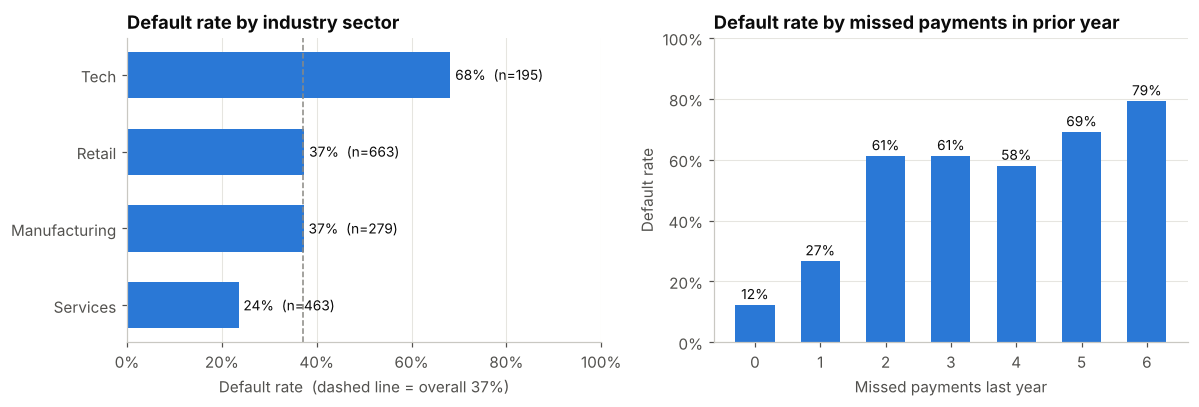

,mean,size
IndustrySector,,
Services,0.235,463
Manufacturing,0.373,279
Retail,0.374,663
Tech,0.682,195


In [7]:
train = X_train.assign(Defaulted=y_train)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
rate_sector = train.groupby("IndustrySector")[TARGET].agg(["mean", "size"]).sort_values("mean")
ax = axes[0]
ax.barh(rate_sector.index, rate_sector["mean"], color=BLUE, height=0.6)
ax.axvline(y_train.mean(), color=GREY, ls="--", lw=1)
for i, (r, n) in enumerate(zip(rate_sector["mean"], rate_sector["size"])):
    ax.text(r + 0.01, i, f"{r:.0%}  (n={n})", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 1); ax.set_title("Default rate by industry sector")
ax.set_xlabel(f"Default rate  (dashed line = overall {y_train.mean():.0%})")
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1)); ax.grid(axis="y", visible=False)

rate_miss = train.groupby("MissedPaymentsLastYear")[TARGET].agg(["mean", "size"])
ax = axes[1]
ax.bar(rate_miss.index, rate_miss["mean"], color=BLUE, width=0.6)
for x_, (r, n) in zip(rate_miss.index, rate_miss.values):
    ax.text(x_, r + 0.02, f"{r:.0%}", ha="center", fontsize=9, color=INK)
ax.set_ylim(0, 1); ax.set_title("Default rate by missed payments in prior year")
ax.set_xlabel("Missed payments last year"); ax.set_ylabel("Default rate")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1)); ax.grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "fig01_default_rate_by_sector_and_missed_payments")
rate_sector.assign(mean=lambda d: d["mean"].round(3))

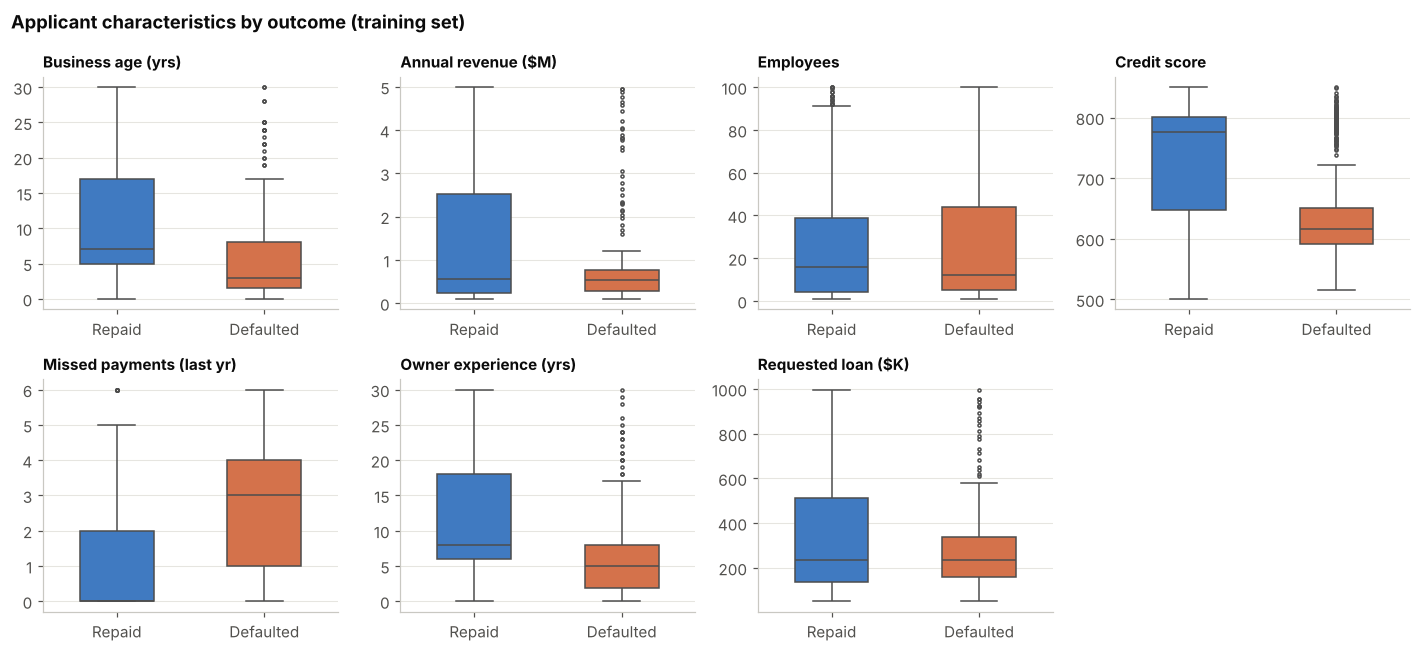

Defaulted,mean_repaid,mean_defaulted,corr_with_default
CreditScore,736.865,638.854,-0.501
OwnerExperience,11.556,5.516,-0.401
BusinessAge,10.693,5.495,-0.333
AnnualRevenue,1412273.754,684342.563,-0.264
RequestedLoanAmount,345379.681,267990.723,-0.162
Employees,24.237,26.588,0.044
MissedPaymentsLastYear,1.080,2.788,0.456


In [8]:
labels = {"BusinessAge": "Business age (yrs)", "AnnualRevenue": "Annual revenue ($M)",
          "Employees": "Employees", "CreditScore": "Credit score",
          "MissedPaymentsLastYear": "Missed payments (last yr)",
          "OwnerExperience": "Owner experience (yrs)", "RequestedLoanAmount": "Requested loan ($K)"}
plot_df = train.copy()
plot_df["AnnualRevenue"] /= 1e6; plot_df["RequestedLoanAmount"] /= 1e3
plot_df["Outcome"] = plot_df[TARGET].map({0: "Repaid", 1: "Defaulted"})

fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, col in zip(axes.flat, NUMERIC):
    sns.boxplot(data=plot_df, x="Outcome", y=col, hue="Outcome", order=["Repaid", "Defaulted"],
                palette={"Repaid": BLUE, "Defaulted": ORANGE}, width=0.5, fliersize=2,
                linewidth=1, ax=ax, legend=False)
    ax.set_title(labels[col], fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
    ax.grid(axis="x", visible=False)
axes.flat[-1].axis("off")
fig.suptitle("Applicant characteristics by outcome (training set)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout(); save(fig, "fig02_feature_distributions_by_outcome")

# Mean of each feature by outcome + point-biserial correlation with the target
by_outcome = train.groupby(TARGET)[NUMERIC].mean().T.rename(columns={0: "mean_repaid", 1: "mean_defaulted"})
by_outcome["corr_with_default"] = train[NUMERIC].corrwith(train[TARGET])
by_outcome.sort_values("corr_with_default").round(3)

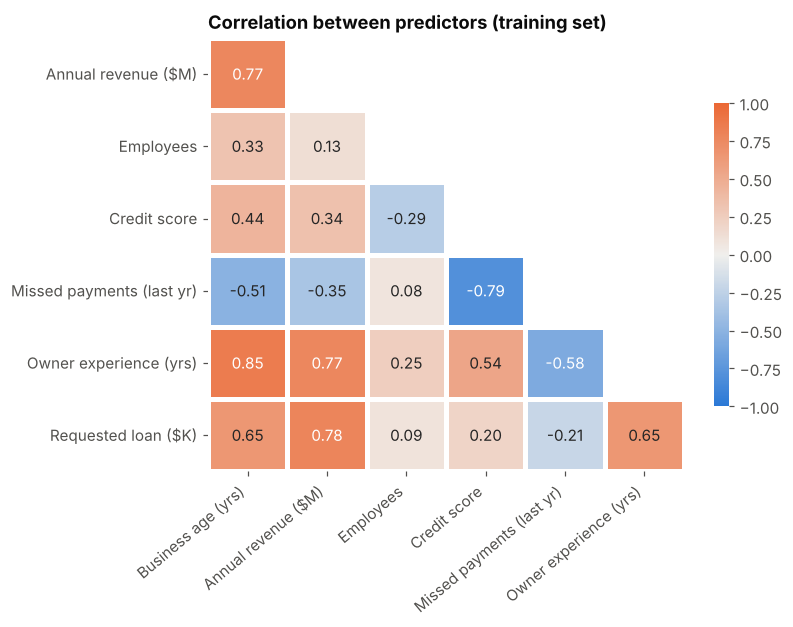

In [9]:
corr = X_train[NUMERIC].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=0)
fig, ax = plt.subplots(figsize=(7.5, 5.8))
corr_plot = corr.iloc[1:, :-1]; mask = mask[1:, :-1]
sns.heatmap(corr_plot, mask=mask, annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor="white", cbar_kws={"shrink": 0.7},
            xticklabels=[labels[c] for c in NUMERIC[:-1]], yticklabels=[labels[c] for c in NUMERIC[1:]], ax=ax)
ax.set_title("Correlation between predictors (training set)"); ax.grid(False)
plt.xticks(rotation=40, ha="right")
fig.tight_layout(); save(fig, "fig03_predictor_correlations")

**EDA observations (training set, descriptive associations only)**

- Defaulters on average have **lower credit scores, more missed payments, younger businesses, less experienced owners and lower revenue**.
- **Tech-sector applicants default far more often** than other sectors; Services the least.
- Default rate jumps sharply between **one and two missed payments** in the prior year.
- Several predictors are strongly inter-correlated (`BusinessAge`, `OwnerExperience`, `AnnualRevenue`, `RequestedLoanAmount`; and `CreditScore` with `MissedPaymentsLastYear`), so individual model coefficients or importances should not be read as independent effects.

## 5. Feature Selection & Leakage Prevention

### 5.1 Feature availability at prediction time
| Feature | Known at application? | Used |
|---|---|---|
| `ID` | n/a (row index) | No |
| `Defaulted` | No — it is the outcome | **Target only** |
| `MissedPaymentsLastYear` | Yes — refers to the 12 months *before* application (assumed; see Limitations) | Yes |
| All other attributes | Yes | Yes |

No post-outcome variables are present in the file. `MissedPaymentsLastYear` is the one field whose timing must be confirmed with the data owner: if it were measured *after* the loan was issued it would be leakage and should be removed.

### 5.2 Feature sets
- **Full model:** all 7 numeric features + `IndustrySector` (one-hot encoded, Manufacturing as the reference category).
- **Reduced model** (kept from the original project): `CreditScore`, `RequestedLoanAmount`, `MissedPaymentsLastYear`, `AnnualRevenue`. The original notebook described this subset as chosen by "predictive importance"; it was in fact an analyst-chosen subset. The training-set EDA above shows that `OwnerExperience` and `IndustrySector` are more strongly associated with default than `RequestedLoanAmount`, so the reduced set is tested here as a *simplicity* trade-off, not as an importance-ranked set.

### 5.3 Leakage controls
1. **Target excluded from every input**, including clustering (corrects the original error, demonstrated below).
2. **Split before learning:** scaling, encoding and clustering are fitted on training data only.
3. **Pipelines inside cross-validation:** every preprocessing step is refit within each CV fold, so validation folds never influence the transformations.
4. **Untouched test set:** used once, after the model was selected on cross-validation.
5. **Model selection rule fixed in advance** (Section 6.2).

In [10]:
# Demonstration of the original error (training data only).
# Original notebook: K-Means was fit on a frame that still contained `Defaulted`,
# and the cluster labels were then used as model inputs.
enc_demo = pd.get_dummies(X_train, columns=CATEGORICAL, drop_first=True, dtype=int)
enc_demo[NUMERIC] = StandardScaler().fit_transform(enc_demo[NUMERIC])
leaky_input = enc_demo.assign(Defaulted=y_train.values)

demo = {}
for name, frame in [("WITH target (original, invalid)", leaky_input), ("WITHOUT target (corrected)", enc_demo)]:
    lab = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(frame)
    demo[name] = {"silhouette": round(silhouette_score(frame, lab), 3),
                  "cluster default rates": sorted(pd.Series(y_train.values).groupby(lab).mean().round(2).tolist())}
pd.DataFrame(demo).T

,silhouette,cluster default rates
"WITH target (original, invalid)",0.478,"[0.08, 0.16, 0.52, 0.74]"
WITHOUT target (corrected),0.496,"[0.08, 0.16, 0.52, 0.74]"


**What the audit found, and how much it mattered.** The original notebook made two compounding errors in the clustering step: (1) `Defaulted` was part of the K-Means input, and (2) inside the loop over k = 3, 4, 5, each run's cluster labels were appended to the same frame, so the k = 4 run clustered on the k = 3 labels and the k = 5 run on both. The cluster-label columns were then passed to the "Full" classifiers as predictors.

Re-running the original code during the audit, on the original 95% sample, reproduces its reported silhouette scores exactly (0.353 / 0.518 / 0.471 for k = 3 / 4 / 5). Isolating each error on that same sample:

| K-Means input | k = 3 | k = 4 | k = 5 |
|---|---|---|---|
| Original (target + chained cluster labels) | 0.353 | 0.518 | 0.471 |
| Target only | 0.353 | 0.478 | 0.411 |
| Features only (correct) | 0.353 | 0.495 | 0.467 |

*These audit figures come from re-running the original notebook. That re-run is not repeated here because the original sampling seed was the author's student ID, which has been removed from the public version.*

So the reported k = 4 score was inflated by the chained labels, and the target column itself was an invalid input. The demonstration in the cell above, on the training set, shows that the target happened not to move the four clusters much in this dataset (identical per-cluster default rates) — the segment structure is genuine. The effect on the classifiers was also small: removing the cluster columns left the original Decision Tree's CV ROC-AUC unchanged (0.8125, it never split on them) and moved the Neural Network from 0.8146 to 0.8164. **The original scores were therefore not inflated by leakage, but the method was invalid** and would leak in general; it is removed below. The corrected workflow never exposes the target to clustering and does not feed cluster labels to the classifiers.

## 6. Model Development

### 6.1 Applicant segmentation with K-Means (unsupervised)

K-Means is fitted on the seven **standardised numeric application features of the training set only** (the target is never an input). The one-hot sector dummies are left out because 0/1 indicators mixed with z-scores distort Euclidean distances. The number of segments is chosen by silhouette score over k = 2–6. Default rates are attached **afterwards**, purely to describe the segments.

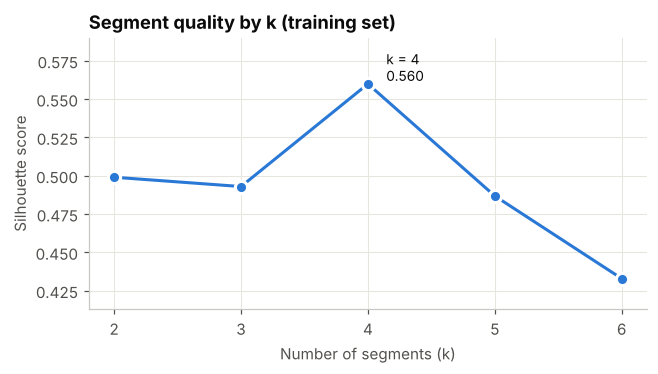

,2,3,4,5,6
silhouette,0.499,0.493,0.56,0.487,0.433


In [11]:
seg_scores = {}
for k in range(2, 7):
    seg = Pipeline([("scale", StandardScaler()), ("km", KMeans(n_clusters=k, n_init=10, random_state=SEED))])
    lab = seg.fit_predict(X_train[NUMERIC])
    seg_scores[k] = silhouette_score(seg.named_steps["scale"].transform(X_train[NUMERIC]), lab)
seg_scores = pd.Series(seg_scores, name="silhouette")
BEST_K = int(seg_scores.idxmax())

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(seg_scores.index, seg_scores.values, color=BLUE, lw=2, marker="o", ms=8,
        markeredgecolor="white", markeredgewidth=2)
ax.annotate(f"k = {BEST_K}\n{seg_scores.max():.3f}", (BEST_K, seg_scores.max()),
            xytext=(12, 2), textcoords="offset points", fontsize=9, color=INK)
ax.set_ylim(seg_scores.min() - 0.02, seg_scores.max() + 0.03)
ax.set_xticks(seg_scores.index); ax.set_xlabel("Number of segments (k)"); ax.set_ylabel("Silhouette score")
ax.set_title("Segment quality by k (training set)")
fig.tight_layout(); save(fig, "fig04_kmeans_silhouette")
seg_scores.round(3).to_frame().T

In [12]:
segmenter = Pipeline([("scale", StandardScaler()),
                      ("km", KMeans(n_clusters=BEST_K, n_init=10, random_state=SEED))])
seg_train = segmenter.fit_predict(X_train[NUMERIC])
seg_test = segmenter.predict(X_test[NUMERIC])          # test applicants assigned with the frozen model

profile = X_train[NUMERIC].assign(Segment=seg_train).groupby("Segment").median()
profile["Applicants (train)"] = pd.Series(seg_train).value_counts().sort_index()
profile["Default rate (train)"] = pd.Series(y_train.values).groupby(seg_train).mean()
profile["Default rate (test)"] = pd.Series(y_test.values).groupby(seg_test).mean()
profile["Tech share (train)"] = (X_train["IndustrySector"].eq("Tech")).groupby(seg_train).mean().values

# Order segments by training default rate and give them descriptive labels
profile = profile.sort_values("Default rate (train)")
order = list(profile.index)
profile.index = [f"S{i+1}" for i in range(len(order))]
remap = {old: new for old, new in zip(order, profile.index)}
profile.round({"AnnualRevenue": 0, "RequestedLoanAmount": 0, "Default rate (train)": 3,
               "Default rate (test)": 3, "Tech share (train)": 3})

,BusinessAge,AnnualRevenue,Employees,CreditScore,MissedPaymentsLastYear,OwnerExperience,RequestedLoanAmount,Applicants (train),Default rate (train),Default rate (test),Tech share (train)
S1,20.0,3251904.0,30.0,780.0,0.0,20.0,641795.0,398,0.078,0.078,0.000
S2,5.0,203247.0,3.0,800.0,0.0,7.0,126682.0,407,0.157,0.083,0.000
S3,8.0,490684.0,58.0,621.0,2.0,8.0,199588.0,391,0.517,0.538,0.000
S4,1.5,644224.0,8.0,602.0,4.0,1.9,299850.0,404,0.735,0.752,0.483


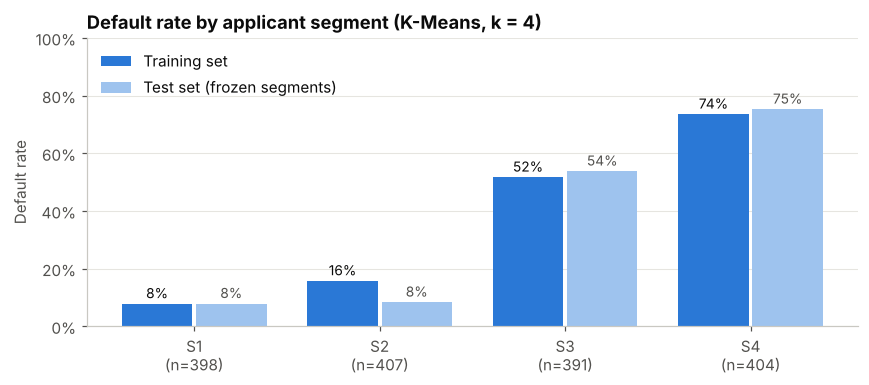

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.6))
xpos = np.arange(len(profile)); w = 0.38
ax.bar(xpos - w/2 - 0.01, profile["Default rate (train)"], w, color=BLUE, label="Training set")
ax.bar(xpos + w/2 + 0.01, profile["Default rate (test)"], w, color="#9ec3ee", label="Test set (frozen segments)")
for i, (a, b) in enumerate(zip(profile["Default rate (train)"], profile["Default rate (test)"])):
    ax.text(i - w/2 - 0.01, a + 0.02, f"{a:.0%}", ha="center", fontsize=9)
    ax.text(i + w/2 + 0.01, b + 0.02, f"{b:.0%}", ha="center", fontsize=9, color=MUTED)
ax.set_xticks(xpos, [f"{s}\n(n={int(n)})" for s, n in zip(profile.index, profile['Applicants (train)'])])
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
ax.set_ylabel("Default rate"); ax.set_title(f"Default rate by applicant segment (K-Means, k = {BEST_K})")
ax.legend(frameon=False, loc="upper left"); ax.grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "fig05_segment_default_rates")

### 6.2 Supervised models

All models are scikit-learn `Pipeline`s, so scaling and one-hot encoding are refit inside every cross-validation fold.

| Model | Role | Settings |
|---|---|---|
| Majority-class baseline | Floor: what "no model" achieves | predicts class prior |
| Logistic Regression (Full) | Interpretable benchmark (added in this revision) | default L2 regularisation |
| Decision Tree (Full / Reduced) | Original project model | `max_depth=4`, `min_samples_leaf=100` (original hyper-parameters) |
| Neural Network (Full / Reduced) | Original project model | MLP, hidden layers (3, 5) (original architecture); `max_iter` raised to 2000 so training converges |

Hyper-parameters are kept from the original project; no tuning is performed, so cross-validation is used purely for **comparison and selection**.

**Selection rule (fixed before results were seen):** choose the model with the highest mean 5-fold cross-validated **ROC-AUC** on the training set. If other models are within **0.01 AUC** of the best, prefer the most interpretable one in this order: Logistic Regression → Decision Tree → Neural Network, and Reduced before Full within a family. ROC-AUC is the primary metric because the business use is to *rank* applicants by risk; the decision threshold is a separate business choice (Section 7.3).

Classification metrics (accuracy, precision, recall, specificity, F1) use the default 0.5 probability threshold. "Positive" = defaulted.

In [14]:
REDUCED = ["CreditScore", "RequestedLoanAmount", "MissedPaymentsLastYear", "AnnualRevenue"]

def preprocessor(numeric, categorical):
    steps = [("num", StandardScaler(), numeric)]
    if categorical:
        steps.append(("cat", OneHotEncoder(drop="first"), categorical))
    return ColumnTransformer(steps)

def make_pipe(estimator, reduced=False):
    pre = preprocessor(REDUCED, []) if reduced else preprocessor(NUMERIC, CATEGORICAL)
    return Pipeline([("prep", pre), ("model", estimator)])

dt = lambda: DecisionTreeClassifier(max_depth=4, min_samples_leaf=100, random_state=SEED)
nn = lambda: MLPClassifier(hidden_layer_sizes=(3, 5), max_iter=2000, random_state=SEED)

models = {
    "Baseline (majority class)": make_pipe(DummyClassifier(strategy="prior")),
    "Logistic Regression (Full)": make_pipe(LogisticRegression(max_iter=1000)),
    "Decision Tree (Full)":       make_pipe(dt()),
    "Decision Tree (Reduced)":    make_pipe(dt(), reduced=True),
    "Neural Network (Full)":      make_pipe(nn()),
    "Neural Network (Reduced)":   make_pipe(nn(), reduced=True),
}
INTERPRETABILITY_ORDER = ["Logistic Regression (Full)", "Decision Tree (Reduced)", "Decision Tree (Full)",
                          "Neural Network (Reduced)", "Neural Network (Full)"]

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "ROC-AUC": "roc_auc", "Accuracy": "accuracy",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": "recall",
    "Specificity": make_scorer(recall_score, pos_label=0),
    "F1": make_scorer(f1_score, zero_division=0),
}
METRICS = list(scoring)

cv_rows, cv_std = {}, {}
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows[name] = {m: res[f"test_{m}"].mean() for m in METRICS}
    cv_std[name] = {m: res[f"test_{m}"].std() for m in METRICS}
cv_mean, cv_sd = pd.DataFrame(cv_rows).T, pd.DataFrame(cv_std).T

cv_table = cv_mean.map(fmt) + " ± " + cv_sd.map(fmt)
cv_table

,ROC-AUC,Accuracy,Precision,Recall,Specificity,F1
Baseline (majority class),0.500 ± 0.000,0.629 ± 0.001,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000
Logistic Regression (Full),0.803 ± 0.032,0.741 ± 0.025,0.644 ± 0.036,0.682 ± 0.044,0.775 ± 0.038,0.661 ± 0.031
Decision Tree (Full),0.806 ± 0.031,0.748 ± 0.033,0.649 ± 0.041,0.700 ± 0.055,0.776 ± 0.029,0.673 ± 0.045
Decision Tree (Reduced),0.793 ± 0.039,0.742 ± 0.042,0.641 ± 0.053,0.695 ± 0.066,0.769 ± 0.041,0.666 ± 0.055
Neural Network (Full),0.804 ± 0.027,0.748 ± 0.027,0.647 ± 0.046,0.719 ± 0.047,0.764 ± 0.052,0.679 ± 0.027
Neural Network (Reduced),0.784 ± 0.032,0.747 ± 0.031,0.630 ± 0.041,0.781 ± 0.033,0.727 ± 0.042,0.697 ± 0.032


In [16]:
# Apply the pre-declared selection rule
candidates = cv_mean.drop(index="Baseline (majority class)")
best_auc = candidates["ROC-AUC"].max()
within = candidates.index[candidates["ROC-AUC"] >= best_auc - 0.01].tolist()
WINNER = next(m for m in INTERPRETABILITY_ORDER if m in within)
print(f"Highest CV ROC-AUC: {candidates['ROC-AUC'].idxmax()} ({best_auc:.4f})")
print(f"Models within 0.01 AUC of best: {within}")
print(f"Selected model (rule applied): {WINNER}  [CV ROC-AUC {cv_mean.loc[WINNER, 'ROC-AUC']:.4f}]")

Highest CV ROC-AUC: Decision Tree (Full) (0.8060)
Models within 0.01 AUC of best: ['Logistic Regression (Full)', 'Decision Tree (Full)', 'Neural Network (Full)']
Selected model (rule applied): Logistic Regression (Full)  [CV ROC-AUC 0.8028]


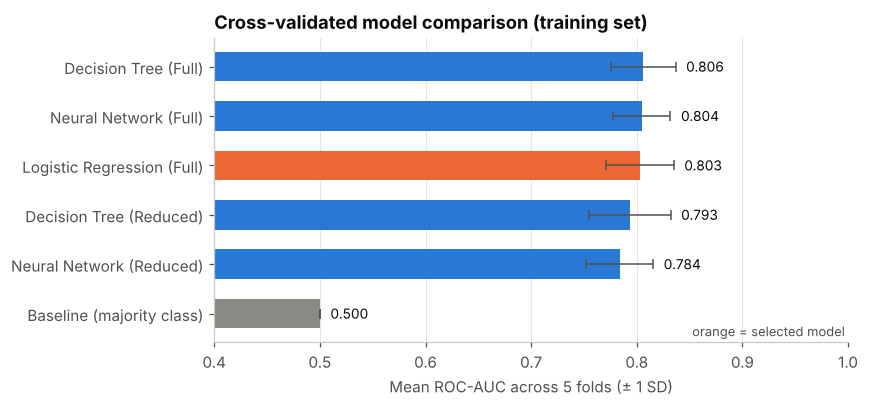

In [17]:
plot_order = cv_mean.sort_values("ROC-AUC").index
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [ORANGE if m == WINNER else (GREY if "Baseline" in m else BLUE) for m in plot_order]
ax.barh(plot_order, cv_mean.loc[plot_order, "ROC-AUC"], xerr=cv_sd.loc[plot_order, "ROC-AUC"],
        color=colors, height=0.6, error_kw={"ecolor": MUTED, "elinewidth": 1, "capsize": 3})
for i, m in enumerate(plot_order):
    v = cv_mean.loc[m, "ROC-AUC"]
    ax.text(v + cv_sd.loc[m, "ROC-AUC"] + 0.01, i, fmt(v), va="center", fontsize=9)
ax.set_xlim(0.4, 1.0); ax.set_xlabel("Mean ROC-AUC across 5 folds (± 1 SD)")
ax.set_title("Cross-validated model comparison (training set)"); ax.grid(axis="y", visible=False)
ax.text(0.995, 0.02, "orange = selected model", transform=ax.transAxes, ha="right", fontsize=8.5, color=MUTED)
fig.tight_layout(); save(fig, "fig06_cv_model_comparison")

## 7. Model Evaluation & Comparison

### 7.1 Fit on the full training set
Each pipeline is now refit on all 1,600 training rows.

### 7.2 Hold-out test set (used once)
The **selected** model's test result is the headline estimate of out-of-sample performance. Test results for the other models are shown for transparency only — they were **not** used to choose the model, and differences between models of a few hundredths on 400 rows are within sampling noise.

In [18]:
fitted, test_rows, test_proba = {}, {}, {}
for name, pipe in models.items():
    fitted[name] = pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]; pred = (p >= 0.5).astype(int)
    test_proba[name] = p
    test_rows[name] = {
        "ROC-AUC": roc_auc_score(y_test, p), "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0), "Recall": recall_score(y_test, pred),
        "Specificity": recall_score(y_test, pred, pos_label=0), "F1": f1_score(y_test, pred, zero_division=0),
    }
test_table = pd.DataFrame(test_rows).T[METRICS]
test_table.style.format(fmt).apply(
    lambda r: ["font-weight: bold; background-color: #fde9df" if r.name == WINNER else "" for _ in r], axis=1)

,ROC-AUC,Accuracy,Precision,Recall,Specificity,F1
Baseline (majority class),0.500,0.630,0.000,0.000,1.000,0.000
Logistic Regression (Full),0.831,0.778,0.679,0.757,0.790,0.716
Decision Tree (Full),0.841,0.780,0.695,0.723,0.813,0.709
Decision Tree (Reduced),0.843,0.773,0.682,0.723,0.802,0.702
Neural Network (Full),0.837,0.775,0.667,0.784,0.770,0.720
Neural Network (Reduced),0.820,0.783,0.656,0.865,0.734,0.746


In [19]:
# Bootstrap 95% confidence interval for the selected model's test ROC-AUC
rng = np.random.default_rng(SEED)
yt, pw = y_test.values, test_proba[WINNER]
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].min() != yt[idx].max():
        boot.append(roc_auc_score(yt[idx], pw[idx]))
AUC_CI = np.percentile(boot, [2.5, 97.5])
print(f"{WINNER}: test ROC-AUC {fmt(test_table.loc[WINNER, 'ROC-AUC'])} "
      f"(bootstrap 95% CI {fmt(AUC_CI[0])}-{fmt(AUC_CI[1])})")

Logistic Regression (Full): test ROC-AUC 0.831 (bootstrap 95% CI 0.784-0.873)


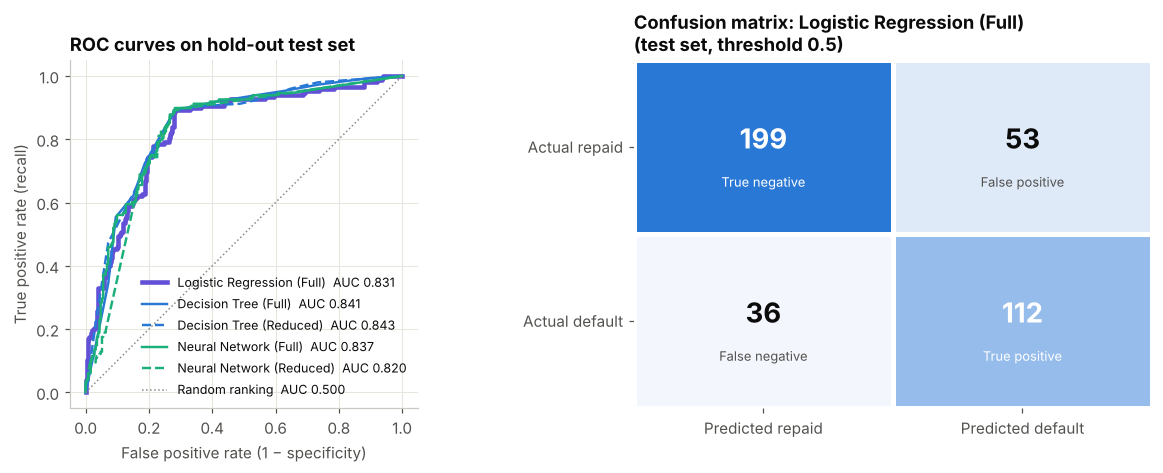

                    Predicted 0  Predicted 1
Actual 0 (repaid)           199           53
Actual 1 (default)           36          112


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
line_styles = {"Logistic Regression (Full)": ("-", "#6250d6"), "Decision Tree (Full)": ("-", BLUE),
               "Decision Tree (Reduced)": ("--", BLUE), "Neural Network (Full)": ("-", "#1baf7a"),
               "Neural Network (Reduced)": ("--", "#1baf7a")}
for name, (ls, c) in line_styles.items():
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    lw = 3 if name == WINNER else 1.6
    ax.plot(fpr, tpr, ls=ls, color=c, lw=lw, label=f"{name}  AUC {fmt(test_table.loc[name, 'ROC-AUC'])}")
ax.plot([0, 1], [0, 1], color=GREY, lw=1, ls=":", label="Random ranking  AUC 0.500")
ax.set_xlabel("False positive rate (1 − specificity)"); ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves on hold-out test set"); ax.legend(frameon=False, fontsize=8.2, loc="lower right")
ax.set_aspect("equal")

ax = axes[1]
cm = confusion_matrix(y_test, (test_proba[WINNER] >= 0.5).astype(int))
blues = LinearSegmentedColormap.from_list("b", ["#f3f7fd", BLUE])
sns.heatmap(cm, annot=False, cmap=blues, cbar=False, linewidths=2, linecolor="white", ax=ax)
names_ = [["True negative", "False positive"], ["False negative", "True positive"]]
for i in range(2):
    for j in range(2):
        ax.text(j + 0.5, i + 0.45, f"{cm[i, j]}", ha="center", va="center", fontsize=18, fontweight="bold",
                color="white" if cm[i, j] > cm.max() * 0.55 else INK)
        ax.text(j + 0.5, i + 0.7, names_[i][j], ha="center", va="center", fontsize=8.5,
                color="white" if cm[i, j] > cm.max() * 0.55 else MUTED)
ax.set_xticklabels(["Predicted repaid", "Predicted default"]); ax.set_yticklabels(["Actual repaid", "Actual default"], rotation=0)
ax.set_title(f"Confusion matrix: {WINNER}\n(test set, threshold 0.5)"); ax.grid(False)
fig.tight_layout(); save(fig, "fig07_test_roc_and_confusion_matrix")
print(pd.DataFrame(cm, index=["Actual 0 (repaid)", "Actual 1 (default)"],
                   columns=["Predicted 0", "Predicted 1"]).to_string())

### 7.3 Decision threshold trade-off (training data, out-of-fold)

The 0.5 threshold is a convention, not a business decision. The chart below shows how recall (share of defaulters flagged) and the share of applicants flagged for review change with the threshold. It is computed from **out-of-fold predictions on the training set**, so the test set is not used to pick a threshold.

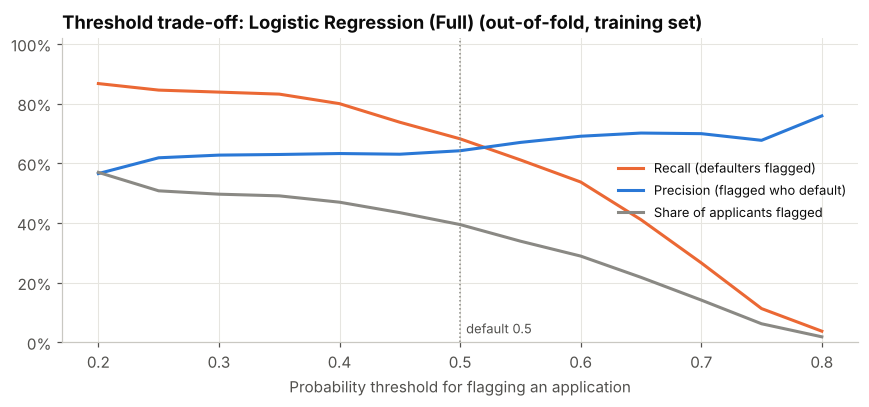

threshold,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80
flagged_share,0.569,0.507,0.496,0.491,0.469,0.434,0.394,0.339,0.289,0.218,0.141,0.062,0.018
recall,0.867,0.845,0.838,0.832,0.800,0.737,0.682,0.611,0.537,0.411,0.266,0.113,0.037
precision,0.565,0.618,0.627,0.629,0.632,0.630,0.642,0.670,0.690,0.701,0.699,0.677,0.759
specificity,0.606,0.692,0.706,0.711,0.726,0.745,0.775,0.822,0.858,0.897,0.932,0.968,0.993


In [21]:
oof = cross_val_predict(models[WINNER], X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thr = np.round(np.arange(0.20, 0.81, 0.05), 2)
tradeoff = pd.DataFrame({
    "threshold": thr,
    "flagged_share": [(oof >= t).mean() for t in thr],
    "recall": [recall_score(y_train, oof >= t) for t in thr],
    "precision": [precision_score(y_train, oof >= t, zero_division=0) for t in thr],
    "specificity": [recall_score(y_train, oof >= t, pos_label=0) for t in thr],
})
fig, ax = plt.subplots(figsize=(8, 3.8))
for col, c, lab in [("recall", ORANGE, "Recall (defaulters flagged)"),
                    ("precision", BLUE, "Precision (flagged who default)"),
                    ("flagged_share", GREY, "Share of applicants flagged")]:
    ax.plot(tradeoff.threshold, tradeoff[col], color=c, lw=2, label=lab)
ax.axvline(0.5, color=GREY, lw=1, ls=":"); ax.text(0.505, 0.03, "default 0.5", fontsize=8.5, color=MUTED)
ax.set_ylim(0, 1.02); ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Probability threshold for flagging an application"); ax.set_title(f"Threshold trade-off: {WINNER} (out-of-fold, training set)")
ax.legend(frameon=False, fontsize=8.5, loc="center right")
fig.tight_layout(); save(fig, "fig08_threshold_tradeoff")
tradeoff.round(3).set_index("threshold").T

### 7.4 What drives the selected model's predictions

Permutation importance measures how much test ROC-AUC drops when one feature's values are shuffled (30 repeats). It describes what the fitted model relies on; because predictors are correlated, a shared signal may be credited to only one of a correlated pair, and importance is not a causal effect. It is computed after model selection and does not influence any choice.

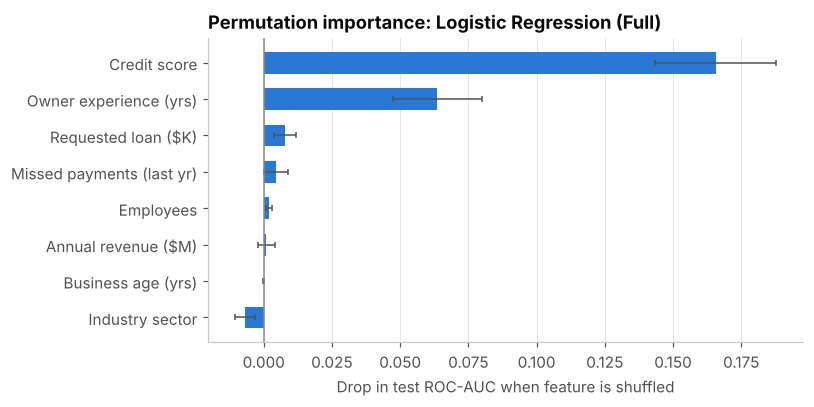

,mean,sd
CreditScore,0.1656,0.0221
OwnerExperience,0.0636,0.0164
RequestedLoanAmount,0.0078,0.0041
MissedPaymentsLastYear,0.0045,0.0045
Employees,0.0019,0.0010
AnnualRevenue,0.0010,0.0032
BusinessAge,-0.0001,0.0002
IndustrySector,-0.0069,0.0036


In [22]:
pi = permutation_importance(fitted[WINNER], X_test, y_test, scoring="roc_auc",
                            n_repeats=30, random_state=SEED)
imp = pd.DataFrame({"mean": pi.importances_mean, "sd": pi.importances_std}, index=X_test.columns)
imp = imp.sort_values("mean")
nice = {**labels, "IndustrySector": "Industry sector"}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh([nice[c] for c in imp.index], imp["mean"], xerr=imp["sd"], color=BLUE, height=0.6,
        error_kw={"ecolor": MUTED, "elinewidth": 1, "capsize": 2})
ax.axvline(0, color=GREY, lw=1)
ax.set_xlabel("Drop in test ROC-AUC when feature is shuffled"); ax.grid(axis="y", visible=False)
ax.set_title(f"Permutation importance: {WINNER}")
fig.tight_layout(); save(fig, "fig09_permutation_importance")
imp.sort_values("mean", ascending=False).round(4)

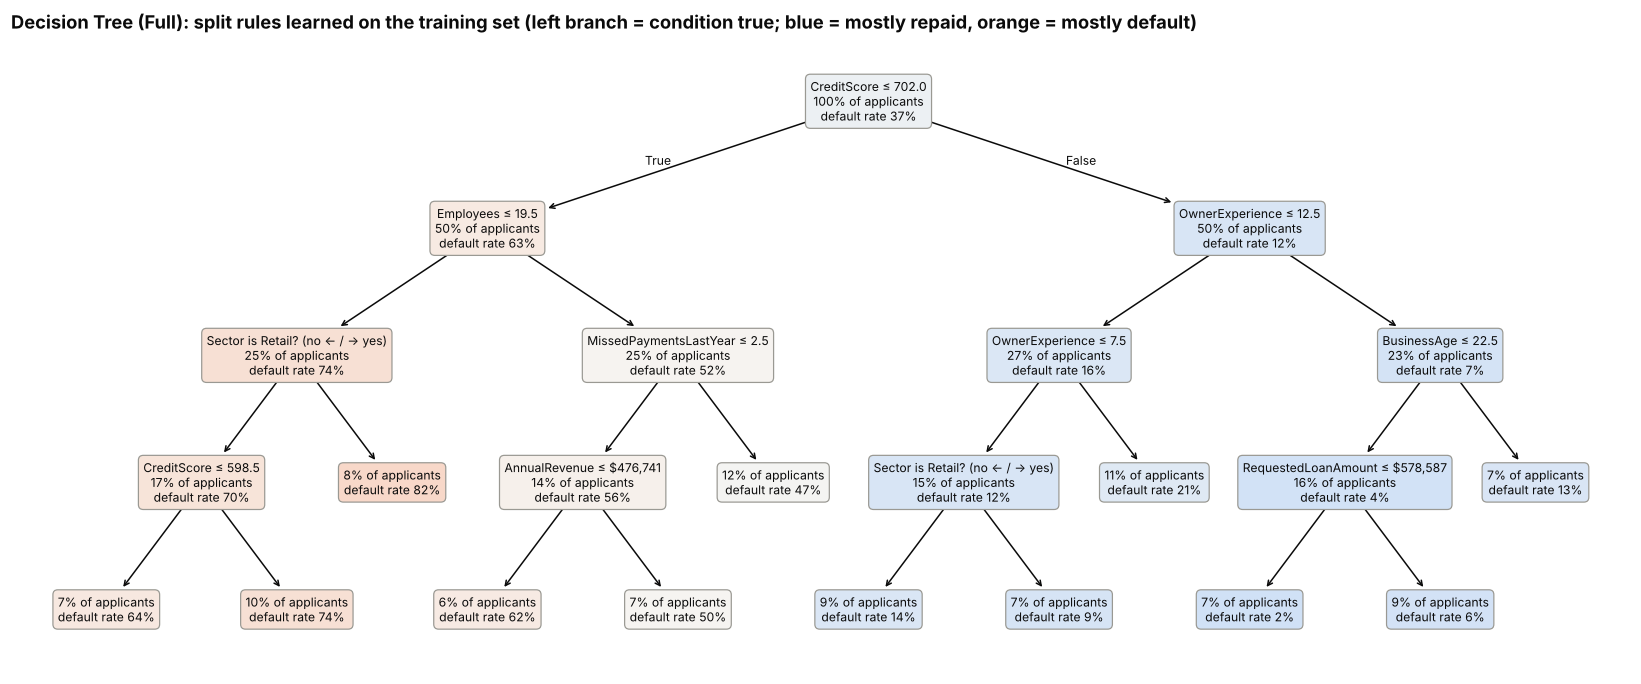

CreditScore               0.869
Employees                 0.080
OwnerExperience           0.021
IndustrySector_Retail     0.012
MissedPaymentsLastYear    0.006
AnnualRevenue             0.006
BusinessAge               0.005
RequestedLoanAmount       0.001
dtype: float64

In [23]:
# Interpretable rules: the original Decision Tree (Full), refit on the training set
tree_pipe = fitted["Decision Tree (Full)"]
feat_names = tree_pipe.named_steps["prep"].get_feature_names_out()
feat_names = [f.split("__")[1] for f in feat_names]
fig, ax = plt.subplots(figsize=(19, 7.5))
tree = tree_pipe.named_steps["model"]
anns = plot_tree(tree, feature_names=feat_names, class_names=["Repaid", "Default"],
                 filled=False, rounded=True, impurity=False, proportion=True, precision=2, fontsize=8, ax=ax)
# Trees are scale-invariant, so each z-score split equals a split in original units: translate for readability
scaler = tree_pipe.named_steps["prep"].named_transformers_["num"]
units = {"AnnualRevenue": "${:,.0f}", "RequestedLoanAmount": "${:,.0f}"}
p_default = tree.tree_.value[:, 0, 1] / tree.tree_.value[:, 0, :].sum(axis=1)
mix = LinearSegmentedColormap.from_list("mix", ["#cfe0f6", "#f6f5f2", "#f9c9b3"])
node_anns = [a for a in anns if "samples" in a.get_text()]
assert len(node_anns) == tree.tree_.node_count
for node, a in enumerate(node_anns):                      # annotations are in node-id (pre-order) sequence
    lines = []
    f_idx = tree.tree_.feature[node]
    if f_idx >= 0:
        fname = feat_names[f_idx]
        if fname in NUMERIC:
            j = NUMERIC.index(fname)
            raw = tree.tree_.threshold[node] * scaler.scale_[j] + scaler.mean_[j]
            lines.append(f"{fname} ≤ " + units.get(fname, "{:,.1f}").format(raw))
        else:
            lines.append(f"Sector is {fname.split('_')[1]}? (no ← / → yes)")
    n_share = tree.tree_.weighted_n_node_samples[node] / tree.tree_.weighted_n_node_samples[0]
    lines += [f"{n_share:.0%} of applicants", f"default rate {p_default[node]:.0%}"]
    a.set_text("\n".join(lines))
    a.set_bbox(dict(boxstyle="round,pad=0.4", fc=mix(p_default[node]), ec="#9a9993", lw=0.8))
ax.set_title("Decision Tree (Full): split rules learned on the training set "
             "(left branch = condition true; blue = mostly repaid, orange = mostly default)", fontsize=12)
save(fig, "fig10_decision_tree_rules")
tree_imp = pd.Series(tree_pipe.named_steps["model"].feature_importances_, index=feat_names)
tree_imp[tree_imp > 0].sort_values(ascending=False).round(3)

In [24]:
# Logistic Regression coefficients (standardised features) - direction of association only
lr = fitted["Logistic Regression (Full)"]
coef = pd.Series(lr.named_steps["model"].coef_[0],
                 index=[f.split("__")[1] for f in lr.named_steps["prep"].get_feature_names_out()])
coef.sort_values().round(3).to_frame("coefficient (log-odds per SD / vs Manufacturing)")

,coefficient (log-odds per SD / vs Manufacturing)
CreditScore,-0.756
OwnerExperience,-0.716
IndustrySector_Tech,-0.520
IndustrySector_Services,-0.358
IndustrySector_Retail,-0.287
AnnualRevenue,-0.129
Employees,-0.043
BusinessAge,0.006
MissedPaymentsLastYear,0.157
RequestedLoanAmount,0.208


In [25]:
# Persist verified results so the README and reports are generated from the same numbers
results = {
    "seed": SEED, "sklearn_version": sklearn.__version__,
    "n_rows": int(len(df_raw)), "n_train": int(len(y_train)), "n_test": int(len(y_test)),
    "default_rate_overall": float(y.mean()), "default_rate_train": float(y_train.mean()),
    "default_rate_test": float(y_test.mean()),
    "sector_default_rate_train": rate_sector["mean"].round(4).to_dict(),
    "missed_default_rate_train": {int(k): round(v, 4) for k, v in rate_miss["mean"].items()},
    "corr_with_default_train": by_outcome["corr_with_default"].round(4).to_dict(),
    "leakage_demo": demo,
    "kmeans_silhouette": {int(k): round(v, 4) for k, v in seg_scores.items()}, "kmeans_best_k": BEST_K,
    "segment_profile": json.loads(profile.round(8).to_json(orient="index")),
    "cv_mean": json.loads(cv_mean.round(8).to_json(orient="index")),
    "cv_sd": json.loads(cv_sd.round(8).to_json(orient="index")),
    "winner": WINNER, "within_001": within,
    "test": json.loads(test_table.round(8).to_json(orient="index")),
    "winner_test_auc_ci95": [round(float(a), 8) for a in AUC_CI],
    "winner_confusion_matrix": cm.tolist(),
    "threshold_tradeoff": json.loads(tradeoff.round(8).to_json(orient="records")),
    "permutation_importance": imp["mean"].sort_values(ascending=False).round(8).to_dict(),
    "tree_importance": tree_imp[tree_imp > 0].sort_values(ascending=False).round(4).to_dict(),
    "lr_coefficients": coef.round(4).to_dict(),
}
(RES_DIR / "metrics.json").write_text(json.dumps(results, indent=2))
cv_mean.round(4).to_csv(RES_DIR / "cv_results_mean.csv"); cv_sd.round(4).to_csv(RES_DIR / "cv_results_sd.csv")
test_table.round(4).to_csv(RES_DIR / "test_results.csv")
print("Saved results/metrics.json, cv_results_*.csv, test_results.csv")

Saved results/metrics.json, cv_results_*.csv, test_results.csv


## 8. Key Analytical Findings

All figures are from this execution (seed 42; 1,600 training / 400 test applications).

**1. Three model families perform essentially the same.** Cross-validated ROC-AUC for the Full Logistic Regression, Decision Tree and Neural Network lies between 0.803 and 0.806, with fold-to-fold standard deviations of about 0.03. The differences are far smaller than the noise, so none of the three is demonstrably better. All three clearly beat the majority-class baseline (ROC-AUC 0.500; it flags nobody).

**2. Selected model: Logistic Regression (Full).** Under the pre-declared rule (highest CV ROC-AUC, preferring the more interpretable model within 0.01), Logistic Regression was selected. On the untouched test set it achieved **ROC-AUC 0.831 (bootstrap 95% CI 0.784–0.873), accuracy 77.8%, recall 75.7%, precision 67.9% and specificity 79.0%** at the 0.5 threshold. It flagged 112 of the 148 test defaulters and wrongly flagged 53 of 252 repaying applicants.

**3. Test scores are slightly higher than cross-validation scores.** This reflects sampling variation in a 400-row test set, not a better model; the other models' test AUCs (0.820–0.843) all fall inside the selected model's confidence interval. The cross-validated range (≈0.80) is the more conservative expectation.

**4. The reduced feature set costs some ranking performance.** Dropping to four features lowered CV ROC-AUC (Decision Tree 0.806 → 0.793; Neural Network 0.804 → 0.784). The reduced set omits `OwnerExperience`, the second most influential feature.

**5. Credit score dominates; owner experience is second.** In the selected model, shuffling `CreditScore` lowers test ROC-AUC by 0.166 and `OwnerExperience` by 0.064; every other feature contributes less than 0.01. The Decision Tree (original hyper-parameters, refit on the training set) attributes 87% of its split importance to `CreditScore`; its first split is at a score of 702, with a 63% default rate at or below that score versus 12% above it. `MissedPaymentsLastYear` has a strong raw association with default but adds little once credit score is known, because the two are highly correlated (r = −0.79).

**6. The Tech sector's high default rate is explained by its applicant profile.** Tech applicants default at 68% in the training data versus 37% overall, but once the other attributes are accounted for, sector adds no predictive value (permutation importance ≈ 0, and the Tech coefficient relative to Manufacturing is negative). Tech applicants are concentrated in the young-business, low-credit segment (S4 below). This is a statistical association within this dataset, not evidence about the sector itself.

**7. Four clear applicant segments with very different default rates.** K-Means on application features alone (silhouette 0.560 at k = 4) finds:

| Segment | Profile (training-set medians) | Default rate: train / test |
|---|---|---|
| S1 | Established, larger firms: 20 yrs old, $3.25M revenue, credit 780, 0 missed payments | 8% / 8% |
| S2 | Young, small firms with strong credit: 5 yrs, $203K revenue, 3 staff, credit 800 | 16% / 8% |
| S3 | Mid-size, weaker credit: 58 staff, credit 621, 2 missed payments | 52% / 54% |
| S4 | Very young, inexperienced owners, poor credit: 1.5 yrs, owner experience 1.9 yrs, credit 602, 4 missed payments; 48% Tech | 74% / 75% |

Segment default rates carry over closely to the unseen test set (S2 less so; its test group is small).

**8. Comparison with the original submission.** The original reported CV ROC-AUC of 0.8125 (Decision Tree) and 0.8146 (Neural Network) and declared the Neural Network the winner. Those scores were not inflated by the clustering leak (Section 5), but the "winner" was decided by a 0.002 AUC difference that is well within noise, and two of its reported metrics ("Probability Measure" and "Entropy") were not valid model-evaluation measures. The corrected results are of similar magnitude and are now backed by a hold-out test.

## 9. Business Implications

- **Risk-ranking for review prioritisation.** A model with test ROC-AUC ≈ 0.83 ranks a randomly chosen defaulter above a randomly chosen repayer about 83% of the time. This is useful for **ordering** applications for analyst attention, not for automated approve/decline decisions.
- **The threshold is a policy choice.** Using out-of-fold training predictions: flagging at 0.5 sends 39% of applicants to review and catches 68% of defaulters; lowering the threshold to 0.30 sends 50% to review and catches 84%; raising it to 0.60 sends 29% and catches 54%. The right setting depends on the relative cost of a missed default versus an unnecessary review — figures the lender would supply; none are assumed here.
- **A simple, explainable model is enough here.** Logistic Regression matched the Neural Network, and its direction-of-effect coefficients can be explained to underwriters, applicants and auditors — a practical advantage in regulated lending.
- **Segments give an explainable portfolio view.** The four segments describe *who* applies and how risk concentrates, which can support reporting and review-queue design even without a predictive model.
- **Transferable workflow.** The same leakage-safe process — define the decision, confirm what is known at decision time, split before learning, select by a pre-declared rule, report uncertainty — applies to other experience and operations analytics problems, such as prioritising client-service follow-ups.

These are predictive associations. Nothing here shows that changing a borrower attribute would change that borrower's likelihood of default.

## 10. Limitations & Recommendations

**Limitations**
- **Data provenance.** The dataset was supplied for coursework; its origin, time period and collection method are undocumented, and its clean, well-separated structure suggests it may be synthetic. Results may not transfer to real lending data.
- **Feature timing.** `MissedPaymentsLastYear` is assumed to describe the year before application. If it were recorded after funding it would be leakage.
- **Small sample.** 2,000 applications (400 in test) give wide uncertainty: the test ROC-AUC 95% interval spans about 0.09.
- **No out-of-time validation.** The split is random; real credit models must be validated on later applications, because default patterns shift with economic conditions.
- **No hyper-parameter tuning.** The original settings were kept to preserve the project; tuning (inside cross-validation) might improve the tree or network slightly.
- **Calibration and fairness not assessed.** Predicted probabilities have not been checked for calibration, and the data contains no protected-attribute information to test for disparate impact, which any real credit model would require.
- **Selection bias.** Outcomes are only observed for funded loans; declined applicants are absent (reject inference is not addressed).

**Recommendations**
1. Confirm the dataset's source and the timing of `MissedPaymentsLastYear` before any use beyond demonstration.
2. Validate on a later time period and check probability calibration.
3. Set the flagging threshold with the business, using real review costs and loss estimates.
4. Add fairness and compliance review (e.g., fair-lending testing, adverse-action reason codes) before any operational use.
5. If more data is available, re-tune the models inside cross-validation and re-test on fresh hold-out data.

**This project is an analytical prototype. It is not validated for production credit decisions.**